# Laboratorio 3 — Proyecto final de modelación
**Especialización en Analítica Estratégica de Datos · Estadística para Analítica de Datos · UPTC**
Profesor: Duván Cataño

**Equipo:** Edwart Stevens González Ríos · Karen Julieth Hernández Chaparro · Deisy Carolina Monroy Gutiérrez

**Base de datos:** Encuesta de afectación digital de entidades públicas por el terremoto del 10 de agosto de 2026 (MinTIC), cruzada con el
índice de pobreza multidimensional municipal del DANE (2018). Continúa los Laboratorios 1 (EDA y propuesta de modelación) y 2 (estadística
descriptiva e hipótesis de asociación).

**Contenido:** 1. Introducción y objetivo · 2. Descripción de variables · 3. Limpieza y preprocesamiento · 4. Análisis exploratorio (EDA) ·
5. Pruebas de hipótesis · 6. Construcción de pipelines · 7. Entrenamiento de modelos · 8. Evaluación · 9. Conclusiones.

Los resultados numéricos se redondean a **cuatro cifras decimales**. Al final, el notebook guarda los modelos en `models/` y la base de
modelación en `data/processed/base_lab3.csv`, que usa la aplicación de Streamlit (`app/app.py`).

### Instalación de librerías
Ejecute esta celda primero. Revisa qué librerías faltan en el Python que usa el notebook (Colab, VS Code o Jupyter) y las instala.
Si al final pide reiniciar, use **Restart** en el kernel y vuelva a ejecutar todo desde el inicio.

In [1]:
import sys, subprocess, importlib, importlib.util
REQUERIDAS = {'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib', 'seaborn': 'seaborn', 'scipy': 'scipy',
              'sklearn': 'scikit-learn', 'statsmodels': 'statsmodels', 'joblib': 'joblib'}   # módulo -> paquete de pip
faltantes = [pip for mod, pip in REQUERIDAS.items() if importlib.util.find_spec(mod) is None]
if faltantes:
    print('Instalando:', ', '.join(faltantes))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *faltantes])
    importlib.invalidate_caches()
    print('Instalación terminada.')
else:
    print('Todas las librerías están instaladas.')
print('Python en uso:', sys.executable)

Todas las librerías están instaladas.
Python en uso: /usr/local/bin/python3.13


In [2]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
import joblib, sklearn
from sklearn import set_config
set_config(display='diagram')   # los pipelines se muestran como diagrama interactivo (clic en cada caja para desplegarla)
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, RepeatedKFold, RepeatedStratifiedKFold,
                                     cross_validate, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report, ConfusionMatrixDisplay)
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 80); pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 70)
pd.set_option('display.float_format', lambda v: f'{v:.4f}')
R = lambda v: round(float(v), 4)          # redondeo a 4 decimales
SEMILLA = 42                               # reproducibilidad de particiones y validación cruzada

AZUL, GRIS, NARANJA = '#2a78d6', '#9a9890', '#eb6834'
SEQ = ['#9ec5f4', '#6da7ec', '#3987e5', '#1c5cab', '#0d366b']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25,
                     'axes.axisbelow': True, 'axes.titleweight': 'bold', 'axes.titlesize': 11, 'font.size': 9})
print('scikit-learn', sklearn.__version__)

scikit-learn 1.9.1


### Carga de los insumos del Laboratorio 2
El Laboratorio 3 **no repite** la limpieza de los laboratorios anteriores: lee `data/processed/base_lab2.csv`, que exporta el notebook
`02_Lab2_Estadistica_Asociacion.ipynb` (408 entidades con IPM del DANE, variables derivadas e índice de vulnerabilidad). Si el archivo no
existe, ejecute primero los notebooks 01 y 02 (*Run All*).

In [3]:
# Raíz del proyecto = la primera carpeta (actual o superior) que contiene data/
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data').is_dir()), Path.cwd())
PROC, MODELOS = RAIZ / 'data' / 'processed', RAIZ / 'models'
MODELOS.mkdir(exist_ok=True)
if not (PROC / 'base_lab2.csv').exists():
    raise FileNotFoundError('Falta data/processed/base_lab2.csv: ejecute primero los notebooks 01 y 02.')
base = pd.read_csv(PROC / 'base_lab2.csv', dtype={'cod_dpto': str, 'cod_mpio': str})
ORD_OBJ = ['Sin afectación TIC', 'Bajo', 'Moderado', 'Alto', 'Crítico']
base['nivel_afectacion_cat'] = pd.Categorical(base['nivel_afectacion_cat'], ORD_OBJ, ordered=True)
print('Base del Lab 2:', base.shape)

Base del Lab 2: (408, 84)


## 1. Introducción y objetivo

El 10 de agosto de 2026 un sismo de magnitud 7,4 con epicentro en San José del Palmar (Chocó) afectó a cinco departamentos. MinTIC encuestó
a 409 entidades públicas sobre el estado de su conectividad, energía, sistemas de información y personal TIC. En los laboratorios anteriores
encontramos que **las variables operativas** (conectividad, estado de los sistemas, personal afectado) son las que más se asocian con el nivel
de afectación declarado, y que **la pobreza del municipio (IPM)** no explica la afectación declarada, pero sí la **fragilidad** de la
infraestructura (Lab 2, L2-6 y L2-7).

Con esos hallazgos planteamos **dos modelos**, uno por cada tipo de problema que pide el laboratorio:

| Tarea | Variable respuesta | Pregunta de negocio | Modelo |
|---|---|---|---|
| **Clasificación** | `alto_critico`: 1 si la entidad declara afectación **Alta o Crítica**, 0 si declara Sin afectación, Baja o Moderada | Con lo que reporta una entidad sobre su conectividad, energía, sistemas y personal, ¿se puede anticipar si está en afectación alta para priorizar la atención? | Regresión logística |
| **Regresión** | `indice_vulnerabilidad`: suma de 5 condiciones desfavorables (sin energía estable, sin fibra óptica, sin póliza, sin planes de contingencia, personal TIC insuficiente), de 0 a 5 | Sin esperar a la encuesta, ¿cuánta fragilidad digital se espera en una entidad según la pobreza de su municipio, su departamento y su tipo? | Regresión lineal |

**Por qué dos clases.** Tras la exposición del Lab 1, el profesor recomendó bajar el objetivo de 5 a 2 clases: las clases extremas tienen
pocas observaciones (47 Sin afectación, 52 Alto) y la agrupación Baja/Alta queda casi balanceada.

**Por qué el índice de vulnerabilidad para la regresión.** Es la única variable de respuesta cuantitativa del proyecto que describe el estado
de la entidad (el IPM es un dato del municipio y la duración del formulario es un metadato). En el Lab 2 resultó **aproximadamente simétrico y
mesocúrtico**, la forma que mejor se ajusta a los supuestos de la regresión lineal. Para evitar fuga de información, **ninguno de sus cinco
componentes** se usa como predictor: el modelo solo usa el territorio y el tipo de entidad.

**Objetivo general:** construir, evaluar y desplegar en Streamlit un modelo de clasificación y uno de regresión que ayuden a MinTIC a
priorizar la atención de las entidades afectadas con un criterio territorial.

## 2. Descripción de variables
Se eligen los predictores con base en la síntesis del Lab 2 (L2-7): se conservan las variables cualitativas operativas con mayor V de Cramér,
los conteos de servicios e infraestructura afectados, el IPM y el índice de vulnerabilidad, y **se descartan** los metadatos del formulario
(duración, días después del sismo, número de respuestas "sin información"), los textos libres y los identificadores.

In [4]:
VARIABLES = pd.DataFrame([
    # variable, rol, modelo, tipo, descripción
    ('alto_critico', 'Respuesta', 'Clasificación', 'Cualitativa binaria', '1 = afectación Alta o Crítica; 0 = Sin afectación, Baja o Moderada'),
    ('indice_vulnerabilidad', 'Respuesta / predictor', 'Regresión (respuesta) y clasificación (predictor)', 'Cuantitativa discreta (0-5)', 'Suma de 5 condiciones desfavorables de la entidad'),
    ('ipm', 'Predictor', 'Ambos', 'Cuantitativa continua', '% de personas en pobreza multidimensional del municipio (DANE, 2018)'),
    ('departamento', 'Predictor', 'Regresión', 'Cualitativa nominal (5)', 'Departamento de la entidad'),
    ('tipo_entidad_g', 'Predictor', 'Ambos', 'Cualitativa nominal (4)', 'Tipo de entidad agrupado: Alcaldía, Institución Educativa, Hospital - ESE, Otra entidad'),
    ('estado_conectividad', 'Predictor', 'Clasificación', 'Cualitativa ordinal (4)', 'Normal, degradada, solo mecanismos alternativos, sin conectividad'),
    ('energia_g', 'Predictor', 'Clasificación', 'Cualitativa ordinal (2)', 'Suministro de energía: normal o intermitente/sin energía'),
    ('personal_afectado', 'Predictor', 'Clasificación', 'Cualitativa nominal (3)', '¿El personal TIC resultó afectado?'),
    ('estado_sistemas', 'Predictor', 'Clasificación', 'Cualitativa nominal (5)', 'Estado de los sistemas de información'),
    ('riesgo_continuidad', 'Predictor', 'Clasificación', 'Cualitativa nominal (4)', '¿La afectación pone en riesgo la continuidad de la operación?'),
    ('sede_contingencia', 'Predictor', 'Clasificación', 'Cualitativa nominal (3)', '¿Requiere una sede alterna de contingencia?'),
    ('zonas_incomunicadas', 'Predictor', 'Clasificación', 'Cualitativa nominal (3)', '¿Hay zonas del municipio incomunicadas?'),
    ('estado_infra', 'Predictor', 'Clasificación', 'Cualitativa ordinal (4)', 'Estado de la infraestructura física'),
    ('n_servicios_caidos', 'Predictor', 'Clasificación', 'Cuantitativa discreta (0-7)', 'Servicios digitales fuera de servicio o con afectaciones'),
    ('n_infra_afectada', 'Predictor', 'Clasificación', 'Cuantitativa discreta', 'Elementos de infraestructura afectados'),
    ('n_sistemas_afectados', 'Predictor', 'Clasificación', 'Cuantitativa discreta', 'Sistemas de información afectados'),
], columns=['Variable', 'Rol', 'Modelo', 'Tipo', 'Descripción'])
display(VARIABLES)

,Variable,Rol,Modelo,Tipo,Descripción
0,alto_critico,Respuesta,Clasificación,Cualitativa binaria,"1 = afectación Alta o Crítica; 0 = Sin afectación, Baja o Moderada"
1,indice_vulnerabilidad,Respuesta / predictor,Regresión (respuesta) y clasificación (predictor),Cuantitativa discreta (0-5),Suma de 5 condiciones desfavorables de la entidad
2,ipm,Predictor,Ambos,Cuantitativa continua,"% de personas en pobreza multidimensional del municipio (DANE, 2018)"
3,departamento,Predictor,Regresión,Cualitativa nominal (5),Departamento de la entidad
4,tipo_entidad_g,Predictor,Ambos,Cualitativa nominal (4),"Tipo de entidad agrupado: Alcaldía, Institución Educativa, Hospita..."
5,estado_conectividad,Predictor,Clasificación,Cualitativa ordinal (4),"Normal, degradada, solo mecanismos alternativos, sin conectividad"
6,energia_g,Predictor,Clasificación,Cualitativa ordinal (2),Suministro de energía: normal o intermitente/sin energía
7,personal_afectado,Predictor,Clasificación,Cualitativa nominal (3),¿El personal TIC resultó afectado?
8,estado_sistemas,Predictor,Clasificación,Cualitativa nominal (5),Estado de los sistemas de información
9,riesgo_continuidad,Predictor,Clasificación,Cualitativa nominal (4),¿La afectación pone en riesgo la continuidad de la operación?


## 3. Limpieza y preprocesamiento
La limpieza general (nombres de columnas, faltantes encubiertos, variables derivadas, cruce con el DANE) se hizo en el Lab 1. Aquí se hacen
los pasos **específicos de la modelación**:

1. **Duplicados:** el Lab 1 encontró entidades que respondieron dos veces. Se identifican por razón social y municipio, y se conserva la
   **última respuesta** (la más actualizada). Si se dejaran, la misma entidad podría quedar en entrenamiento y en prueba y la evaluación sería
   optimista.
2. **Categorías poco frecuentes** (frecuencia esperada < 5 en el Lab 2): se agrupan los tipos de entidad con menos de 10 casos en *Otra
   entidad* y la energía *No* (12 casos) con *intermitente*.
3. **"No se ha podido determinar"** se conserva como categoría propia (decisión del Lab 2): es información (la entidad no sabe su estado), no
   un faltante al azar.
4. **Faltantes reales:** se revisan; los pocos que quedan se imputan **dentro del pipeline** (sección 6), para que la imputación se aprenda solo
   con los datos de entrenamiento.
5. **Transformaciones** (logaritmo de los conteos, escalamiento y codificación one-hot) también van dentro del pipeline.

In [5]:
df = base.copy()
# 1. Duplicados: misma razón social (normalizada) en el mismo municipio -> se conserva la última respuesta
df['clave_entidad'] = df['razon_social'].str.upper().str.strip() + ' | ' + df['municipio']
df = df.sort_values('hora_inicio')
dups = df[df['clave_entidad'].duplicated(keep=False)]
print(f'Registros en entidades repetidas: {len(dups)} ({dups["clave_entidad"].nunique()} entidades)')
dups = dups[['id', 'razon_social', 'municipio', 'departamento', 'hora_inicio', 'nivel_afectacion_cat']]
display(dups)
df = df.drop_duplicates('clave_entidad', keep='last').sort_values('id').reset_index(drop=True)
print('Entidades después de quitar duplicados:', len(df))

Registros en entidades repetidas: 10 (5 entidades)


,id,razon_social,municipio,departamento,hora_inicio,nivel_afectacion_cat
43,49,ALCALDIA MUNICIPAL DE RIOFRIO,RIOFRÍO,VALLE DEL CAUCA,2026-08-21 07:57:18,Moderado
109,115,ALCALDIA MUNICIPAL DE RIOFRIO,RIOFRÍO,VALLE DEL CAUCA,2026-08-24 09:22:53,Moderado
182,188,IE SAN PABLO - Principal,PUEBLO RICO,RISARALDA,2026-08-25 06:30:14,Crítico
191,197,IE INSTITUTO SANTUARIO - SE Marco Fidel Suarez,SANTUARIO,RISARALDA,2026-08-25 08:03:31,Crítico
239,245,IE SANTA EMILIA - SE Frisolera Alta,BELÉN DE UMBRÍA,RISARALDA,2026-08-25 15:17:41,Crítico
241,247,IE SANTA EMILIA - SE Frisolera Alta,BELÉN DE UMBRÍA,RISARALDA,2026-08-25 15:21:18,Crítico
346,353,IE INSTITUTO SANTUARIO - SE Marco Fidel Suarez,SANTUARIO,RISARALDA,2026-08-27 22:11:12,Crítico
362,370,IE SAN PABLO - Principal,PUEBLO RICO,RISARALDA,2026-08-27 23:34:05,Crítico
375,384,IE INDIGENA EBERA KIRISIA DEE - SE JITOCHAKE,PUEBLO RICO,RISARALDA,2026-08-28 01:27:41,Crítico
376,385,IE INDIGENA EBERA KIRISIA DEE - SE Jitochake,PUEBLO RICO,RISARALDA,2026-08-28 01:35:02,Crítico


Entidades después de quitar duplicados: 403


In [6]:
# 2. Recodificación de categorías poco frecuentes
GRUPO_TIPO = {'Alcaldía': 'Alcaldía', 'Institución Educativa': 'Institución Educativa', 'Hospital - ESE': 'Hospital - ESE'}
df['tipo_entidad_g'] = df['tipo_entidad'].map(GRUPO_TIPO).fillna('Otra entidad')
df['energia_g'] = np.where(df['energia_estable'] == 'Sí, normal.', 'Normal', 'Intermitente o sin energía')
# Quitar el punto final de las respuestas para que se lean mejor en tablas y en la app
CAT_TEXTO = ['estado_conectividad', 'personal_afectado', 'estado_sistemas', 'riesgo_continuidad', 'sede_contingencia',
             'zonas_incomunicadas', 'estado_infra']
for c in CAT_TEXTO:
    df[c] = df[c].str.strip().str.rstrip('.')
print(df['tipo_entidad'].value_counts().to_string(), '\n')
print(df['tipo_entidad_g'].value_counts().to_string(), '\n')
print(df['energia_g'].value_counts().to_string())

tipo_entidad
Institución Educativa                      255
Alcaldía                                    76
Hospital - ESE                              28
Otro                                        25
Gobernación                                  9
Instituto descentralizado departamental      6
Instituto descentralizado municipal          4 

tipo_entidad_g
Institución Educativa    255
Alcaldía                  76
Otra entidad              44
Hospital - ESE            28 

energia_g
Normal                        307
Intermitente o sin energía     96


In [7]:
# 3-4. Variables de cada modelo y faltantes
NUM_CLF = ['ipm', 'n_servicios_caidos', 'n_infra_afectada', 'n_sistemas_afectados', 'indice_vulnerabilidad']
CAT_CLF = ['tipo_entidad_g', 'estado_conectividad', 'energia_g', 'personal_afectado', 'estado_sistemas', 'riesgo_continuidad',
           'sede_contingencia', 'zonas_incomunicadas', 'estado_infra']
NUM_REG = ['ipm']
CAT_REG = ['departamento', 'tipo_entidad_g']
Y_CLF, Y_REG = 'alto_critico', 'indice_vulnerabilidad'
df['alto_critico'] = df['nivel_afectacion_cat'].isin(['Alto', 'Crítico']).astype(int)
usadas = list(dict.fromkeys(NUM_CLF + CAT_CLF + NUM_REG + CAT_REG + [Y_CLF, Y_REG]))
falt = df[usadas].isna().sum().rename('Faltantes').to_frame()
falt['%'] = falt['Faltantes'] / len(df) * 100
display(falt[falt['Faltantes'] > 0] if falt['Faltantes'].sum() else 'Sin faltantes en las variables del modelo')
print('"No se ha podido determinar" por variable (se conserva como categoría):')
display(df[CAT_CLF].apply(lambda s: (s == 'No se ha podido determinar').sum()).rename('N° entidades').to_frame().query('`N° entidades` > 0'))

,Faltantes,%
estado_sistemas,1,0.2481
estado_infra,1,0.2481


"No se ha podido determinar" por variable (se conserva como categoría):


,N° entidades
estado_sistemas,202
riesgo_continuidad,73
zonas_incomunicadas,217


**Resultado de la limpieza**

* Había **5 entidades que respondieron dos veces** (10 registros; 4 son colegios de Risaralda del bloque de respuestas idénticas). Se
  conservó la última respuesta de cada una y la base de modelación queda con **403 entidades**. Los otros "repetidos" que señaló el Lab 1
  (por ejemplo, "Concejo Municipal" o "Institución Educativa San José") tienen el mismo nombre, pero están en municipios distintos: son
  entidades diferentes y se conservan.
* El tipo de entidad pasa de 7 a **4 grupos** (Gobernación e institutos descentralizados, con menos de 10 casos cada uno, se unen a *Otra
  entidad*) y la energía pasa a **2 grupos**. Así no quedan columnas one-hot con muy pocos casos.
* Solo hay **2 faltantes reales** (uno en estado de los sistemas y uno en estado de la infraestructura): se imputan con la moda dentro del
  pipeline.
* *"No se ha podido determinar"* es frecuente en estado de los sistemas (202), zonas incomunicadas (217) y riesgo para la continuidad (73).
  Se deja como categoría, porque eliminar esas entidades reduciría la base a la mitad y porque el no saber también describe a la entidad.

## 4. Análisis exploratorio de datos (EDA) orientado a la modelación
El EDA completo está en los Labs 1 y 2. Aquí se revisa lo que importa para modelar: el balance de las variables respuesta, cómo cambian con
cada predictor, la forma de los predictores numéricos y la correlación entre ellos (multicolinealidad).

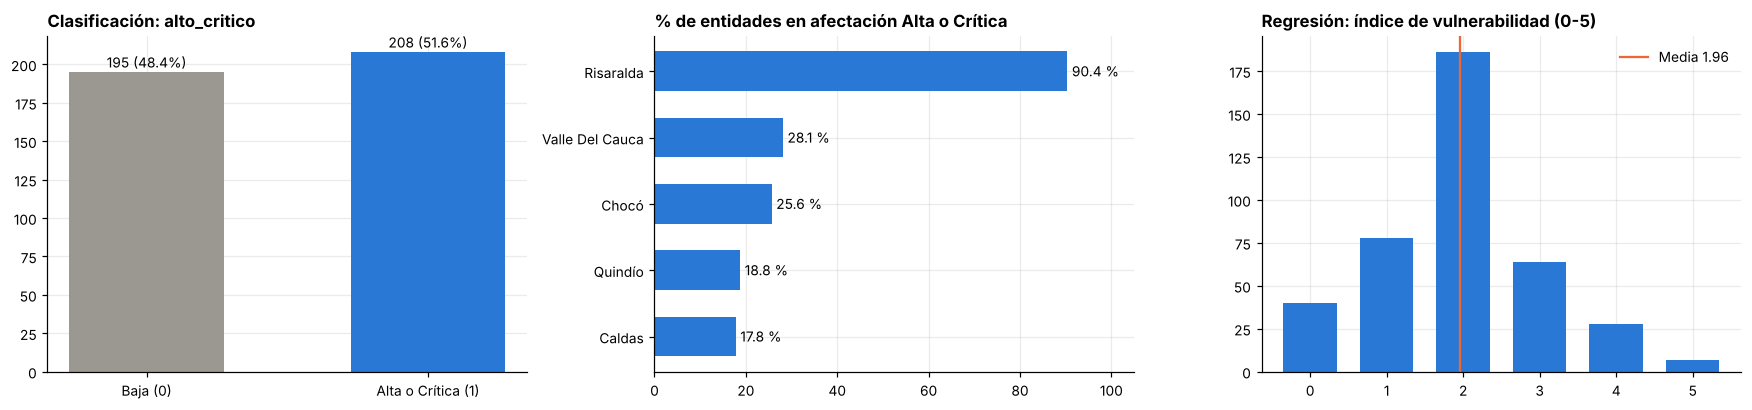

Asimetría del índice: 0.27 | Exceso de curtosis: 0.243


In [8]:
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
# Respuesta de clasificación
vc = df[Y_CLF].map({0: 'Baja (0)', 1: 'Alta o Crítica (1)'}).value_counts().reindex(['Baja (0)', 'Alta o Crítica (1)'])
axs[0].bar(vc.index, vc.values, color=[GRIS, AZUL], width=.55)
for i, v in enumerate(vc.values): axs[0].text(i, v + 3, f'{v} ({v / vc.sum():.1%})', ha='center')
axs[0].set_title('Clasificación: alto_critico', loc='left')
# Por departamento
pdep = df.groupby('departamento')[Y_CLF].mean().sort_values() * 100
axs[1].barh(pdep.index.str.title(), pdep.values, color=AZUL, height=.6)
for i, v in enumerate(pdep.values): axs[1].text(v + 1, i, f'{v:.1f} %', va='center')
axs[1].set_xlim(0, 105); axs[1].set_title('% de entidades en afectación Alta o Crítica', loc='left')
# Respuesta de regresión
cnt = df[Y_REG].value_counts().sort_index()
axs[2].bar(cnt.index, cnt.values, color=AZUL, width=.7)
axs[2].axvline(df[Y_REG].mean(), color=NARANJA, lw=1.5, label=f'Media {df[Y_REG].mean():.2f}')
axs[2].set_title('Regresión: índice de vulnerabilidad (0-5)', loc='left'); axs[2].legend(frameon=False)
plt.tight_layout(); plt.show()
print('Asimetría del índice:', R(stats.skew(df[Y_REG], bias=False)), '| Exceso de curtosis:', R(stats.kurtosis(df[Y_REG], bias=False)))

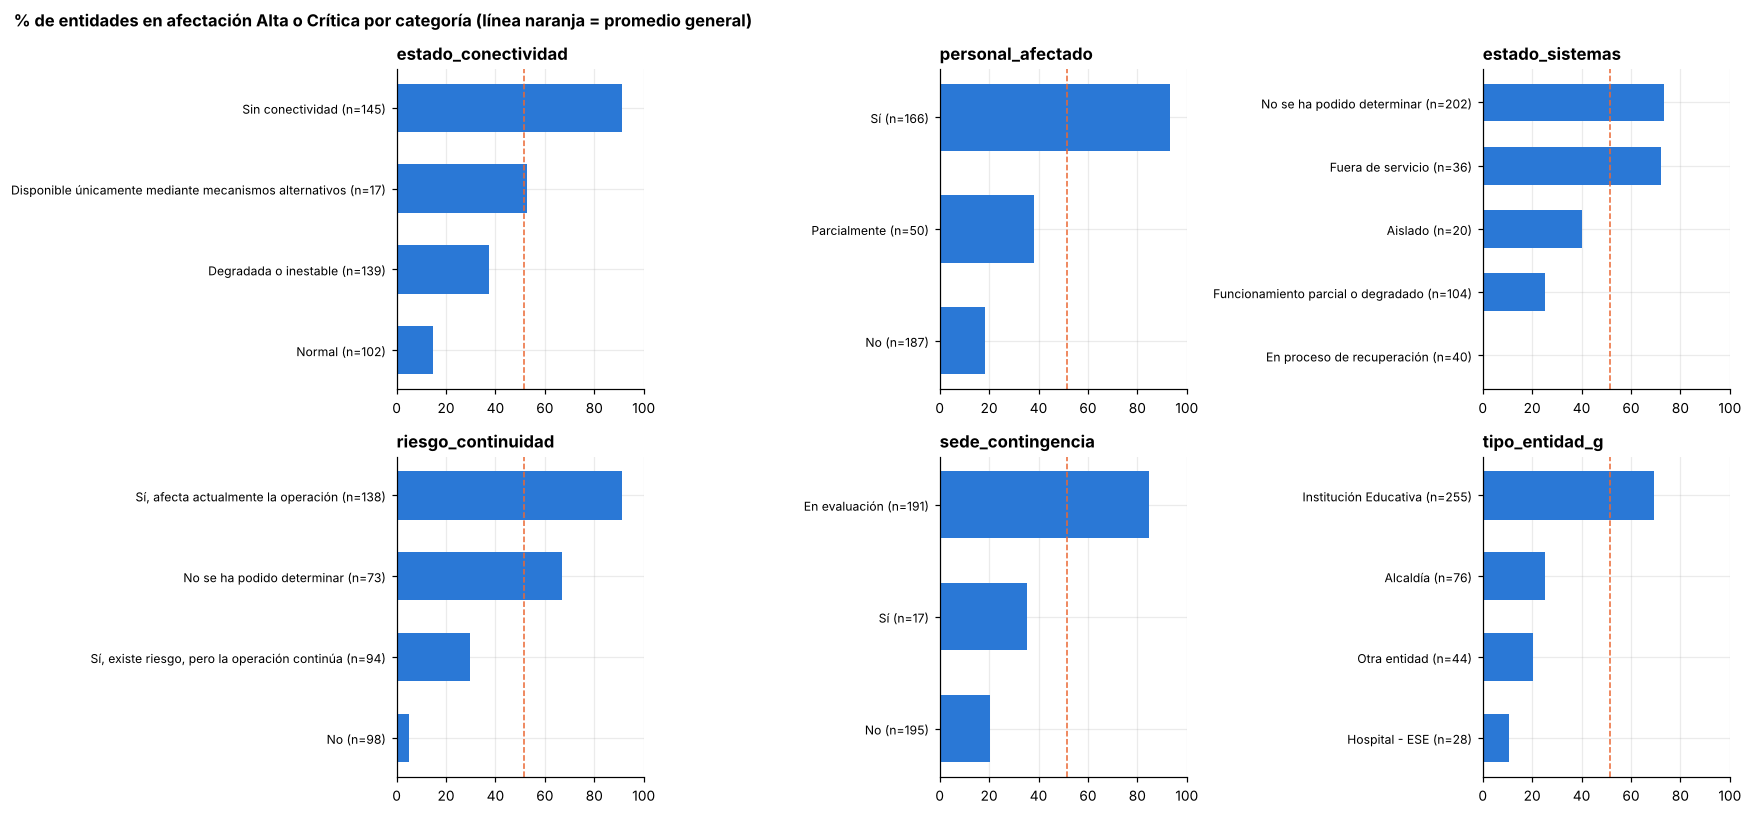

In [9]:
# Proporción de afectación alta según las principales variables cualitativas
fig, axs = plt.subplots(2, 3, figsize=(16, 7.5))
for ax, c in zip(axs.ravel(), ['estado_conectividad', 'personal_afectado', 'estado_sistemas', 'riesgo_continuidad', 'sede_contingencia', 'tipo_entidad_g']):
    t = df.groupby(c)[Y_CLF].agg(['mean', 'size']).sort_values('mean')
    ax.barh([f'{i} (n={n})' for i, n in zip(t.index, t['size'])], t['mean'] * 100, color=AZUL, height=.6)
    ax.axvline(df[Y_CLF].mean() * 100, color=NARANJA, ls='--', lw=1)
    ax.set_xlim(0, 100); ax.set_title(c, loc='left'); ax.tick_params(axis='y', labelsize=8)
fig.suptitle('% de entidades en afectación Alta o Crítica por categoría (línea naranja = promedio general)', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

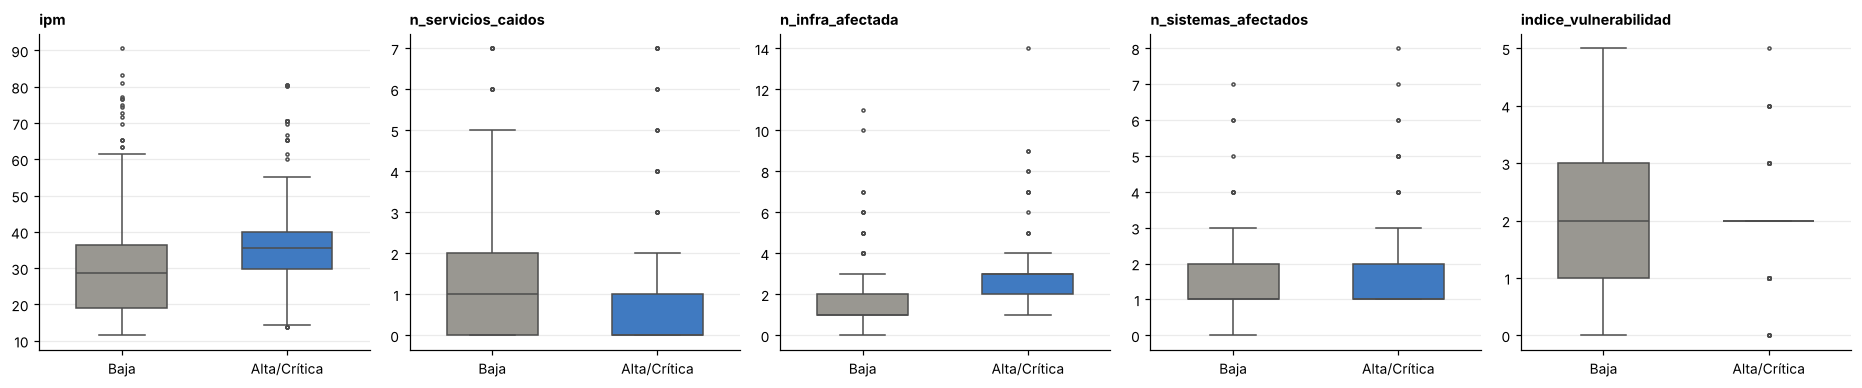

,Asimetría,Exceso de curtosis,Máximo
ipm,1.0937,0.5921,90.6000
n_servicios_caidos,1.7900,2.2251,7.0000
n_infra_afectada,2.4839,9.9514,14.0000
n_sistemas_afectados,2.4930,6.7562,8.0000
indice_vulnerabilidad,0.2700,0.2430,5.0000


In [10]:
# Predictores numéricos según la clase
fig, axs = plt.subplots(1, 5, figsize=(17, 3.6))
for ax, c in zip(axs, NUM_CLF):
    sns.boxplot(data=df, x=Y_CLF, y=c, ax=ax, palette=[GRIS, AZUL], width=.55, fliersize=2)
    ax.set_xticklabels(['Baja', 'Alta/Crítica']); ax.set_xlabel(''); ax.set_title(c, loc='left', fontsize=9.5); ax.set_ylabel('')
plt.tight_layout(); plt.show()
forma = pd.DataFrame({c: {'Asimetría': stats.skew(df[c], bias=False), 'Exceso de curtosis': stats.kurtosis(df[c], bias=False),
                          'Máximo': df[c].max()} for c in NUM_CLF}).T
display(forma)

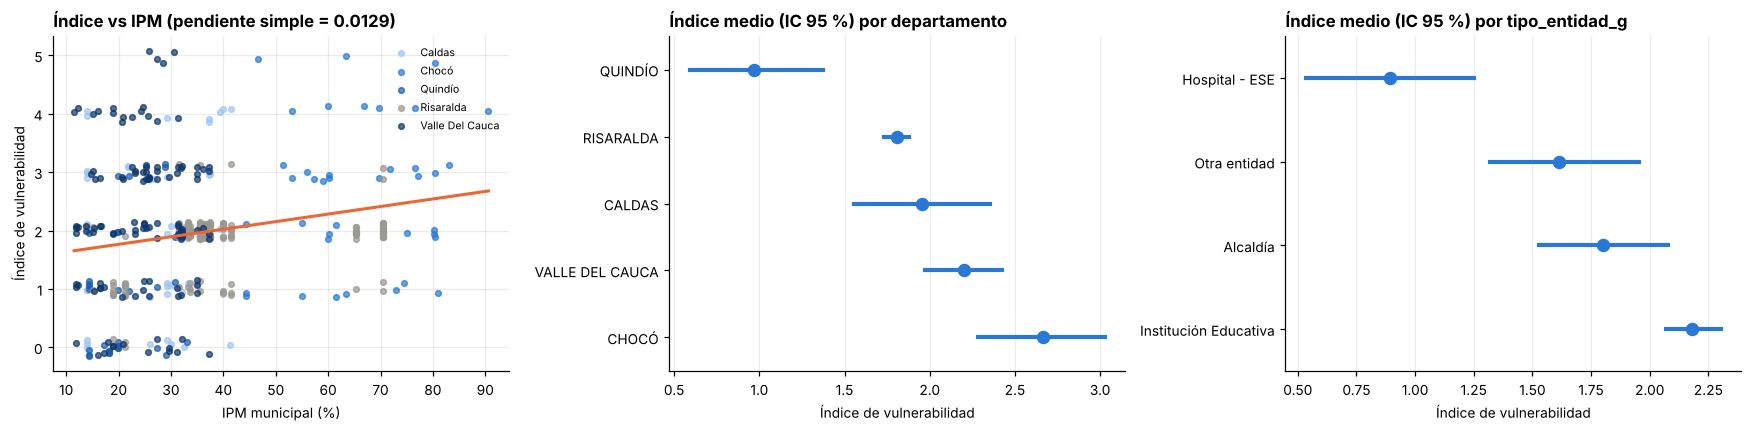

In [11]:
# Regresión: índice de vulnerabilidad frente al IPM, al departamento y al tipo de entidad
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
jit = np.random.default_rng(SEMILLA).uniform(-.15, .15, len(df))
for dep, col in zip(sorted(df['departamento'].unique()), ['#9ec5f4', AZUL, '#1c5cab', GRIS, '#0d366b']):
    m = df['departamento'] == dep
    axs[0].scatter(df.loc[m, 'ipm'], df.loc[m, Y_REG] + jit[m], s=14, alpha=.7, color=col, label=dep.title())
b1, b0 = np.polyfit(df['ipm'], df[Y_REG], 1)
xs = np.linspace(df['ipm'].min(), df['ipm'].max(), 50); axs[0].plot(xs, b0 + b1 * xs, color=NARANJA, lw=2)
axs[0].set_xlabel('IPM municipal (%)'); axs[0].set_ylabel('Índice de vulnerabilidad'); axs[0].legend(frameon=False, fontsize=7)
axs[0].set_title(f'Índice vs IPM (pendiente simple = {b1:.4f})', loc='left')
for ax, c in zip(axs[1:], ['departamento', 'tipo_entidad_g']):
    orden = df.groupby(c)[Y_REG].mean().sort_values().index
    sns.pointplot(data=df, y=c, x=Y_REG, order=orden, ax=ax, color=AZUL, errorbar=('ci', 95), join=False)
    ax.set_title(f'Índice medio (IC 95 %) por {c}', loc='left'); ax.set_ylabel(''); ax.set_xlabel('Índice de vulnerabilidad')
plt.tight_layout(); plt.show()

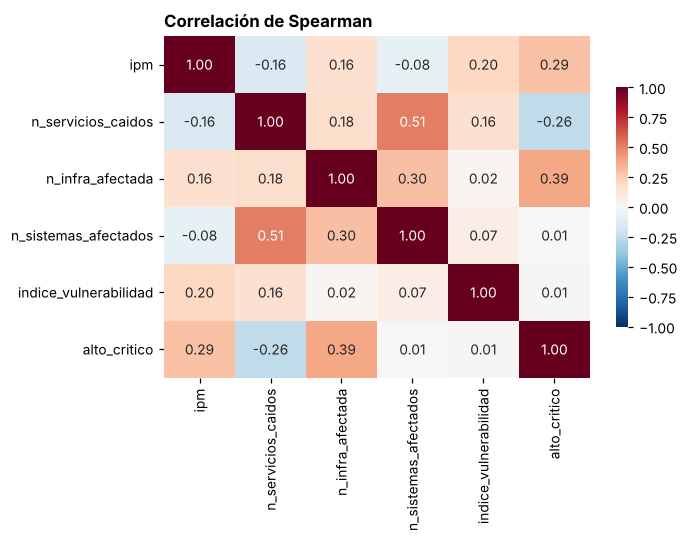

In [12]:
# Correlación de Spearman entre predictores numéricos (multicolinealidad) y con las respuestas
corr = df[NUM_CLF + [Y_CLF]].corr(method='spearman')
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax, cbar_kws={'shrink': .7})
ax.set_title('Correlación de Spearman', loc='left'); plt.tight_layout(); plt.show()

**Hallazgos del EDA para la modelación**

* **Clasificación:** la clase está **balanceada** (51,6 % en afectación Alta o Crítica), así que la accuracy es una métrica informativa.
  El balance global esconde una diferencia territorial: **Risaralda está casi toda en la clase 1** y los otros cuatro departamentos tienen
  entre 17,8 % y 28,1 % (90,4 % en Risaralda). Es el efecto del bloque de colegios con respuestas idénticas identificado en el Lab 1, y se revisa en la evaluación.
* Los predictores cualitativos separan muy bien las clases: *Sin conectividad*, *personal afectado: Sí*, *la afectación ya impide la
  operación* y *sede de contingencia en evaluación* tienen más de 80 % de entidades en la clase 1; *conectividad normal*, *personal no
  afectado* y *sin riesgo* tienen menos de 20 %. *Estado de los sistemas: no se ha podido determinar* también aparece alto, porque es la
  respuesta típica del bloque de Risaralda.
* **Predictores numéricos:** los tres conteos tienen asimetría positiva fuerte (g1 entre 1,79 y 2,49) y colas largas (hasta 14 elementos de
  infraestructura), por eso se transforman con **log(1 + x)** en el pipeline. Sorprende que la clase 1 tenga **menos** servicios caídos
  (mediana 0 frente a 1): los colegios del bloque de Risaralda se declaran en crisis, pero no marcan servicios afectados.
* **Multicolinealidad:** las correlaciones de Spearman entre predictores numéricos son bajas o moderadas; la mayor es 0,51 (servicios
  caídos con sistemas afectados), así que no hay redundancia fuerte.
* **Regresión:** el índice de vulnerabilidad es casi simétrico (g1 = 0,27) y mesocúrtico (exceso de curtosis 0,24), con media cercana a 2.
  Crece con el IPM (pendiente simple de 0,0129 puntos por cada punto de IPM), es más alto en el **Chocó** y más bajo en el **Quindío**, y
  cambia mucho según el tipo de entidad: las **instituciones educativas** son las más vulnerables y los **hospitales** los menos.

## 5. Pruebas de hipótesis e interpretación
Antes de entrenar, se verifica con pruebas formales que cada predictor está asociado con su respuesta. Nivel de significancia **α = 0,05**.
Como se hacen muchas pruebas a la vez, los p-valores se ajustan por **Holm** (control del error de tipo I familiar).

**5.1 Clasificación (`alto_critico`)**
* Predictores cualitativos: **χ² de independencia**. H₀: el predictor y la clase son independientes. Tamaño del efecto: V de Cramér.
  Se reporta el % de celdas con frecuencia esperada < 5 (supuesto de la prueba).
* Predictores cuantitativos: **U de Mann-Whitney** (no paramétrica, porque los conteos son asimétricos; Lab 2). H₀: la distribución del
  predictor es igual en las dos clases. Tamaño del efecto: correlación biserial por rangos.

**5.2 Regresión (`indice_vulnerabilidad`)**
* IPM: **correlación de Spearman** (H₀: ρ = 0), a nivel de entidad y de municipio (para controlar la pseudorreplicación; Lab 2, L2-4).
* Departamento y tipo de entidad: **Kruskal-Wallis** (H₀: la distribución del índice es igual en todos los grupos), porque el índice es
  discreto y no normal dentro de los grupos (se verifica con Shapiro-Wilk).

Los supuestos del modelo lineal (normalidad y homocedasticidad de residuos, independencia, multicolinealidad) y las pruebas t y F de los
coeficientes se evalúan **después de ajustar el modelo**, en la sección 8.

In [13]:
# 5.1 Clasificación
filas = []
for c in CAT_CLF:
    t = pd.crosstab(df[c], df[Y_CLF]); chi2, p, gl, esp = stats.chi2_contingency(t)
    v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
    filas.append({'Predictor': c, 'Prueba': 'χ² de independencia', 'Estadístico': chi2, 'gl': gl, 'p-valor': p, 'Efecto': v,
                  'Medida del efecto': 'V de Cramér', '% esperados < 5': (esp < 5).mean() * 100})
for c in NUM_CLF:
    a, b = df.loc[df[Y_CLF] == 1, c], df.loc[df[Y_CLF] == 0, c]
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    filas.append({'Predictor': c, 'Prueba': 'U de Mann-Whitney', 'Estadístico': u, 'gl': np.nan, 'p-valor': p,
                  'Efecto': 2 * u / (len(a) * len(b)) - 1, 'Medida del efecto': 'Biserial por rangos', '% esperados < 5': np.nan,
                  'Mediana clase 1': a.median(), 'Mediana clase 0': b.median()})
h_clf = pd.DataFrame(filas)
h_clf['p ajustado (Holm)'] = multipletests(h_clf['p-valor'], method='holm')[1]
h_clf['Decisión (α = 0,05)'] = np.where(h_clf['p ajustado (Holm)'] < .05, 'Rechaza H₀: hay asociación', 'No rechaza H₀')
display(h_clf.set_index('Predictor').round(4))

,Prueba,Estadístico,gl,p-valor,Efecto,Medida del efecto,% esperados < 5,Mediana clase 1,Mediana clase 0,p ajustado (Holm),"Decisión (α = 0,05)"
Predictor,,,,,,,,,,,
tipo_entidad_g,χ² de independencia,89.7587,3.0000,0.0000,0.4719,V de Cramér,0.0000,NaN,NaN,0.0000,Rechaza H₀: hay asociación
estado_conectividad,χ² de independencia,157.1015,3.0000,0.0000,0.6244,V de Cramér,0.0000,NaN,NaN,0.0000,Rechaza H₀: hay asociación
energia_g,χ² de independencia,4.4828,1.0000,0.0342,0.1055,V de Cramér,0.0000,NaN,NaN,0.1027,No rechaza H₀
personal_afectado,χ² de independencia,203.3151,2.0000,0.0000,0.7103,V de Cramér,0.0000,NaN,NaN,0.0000,Rechaza H₀: hay asociación
estado_sistemas,χ² de independencia,117.3084,4.0000,0.0000,0.5402,V de Cramér,0.0000,NaN,NaN,0.0000,Rechaza H₀: hay asociación
riesgo_continuidad,χ² de independencia,196.9032,3.0000,0.0000,0.6990,V de Cramér,0.0000,NaN,NaN,0.0000,Rechaza H₀: hay asociación
sede_contingencia,χ² de independencia,161.6525,2.0000,0.0000,0.6333,V de Cramér,0.0000,NaN,NaN,0.0000,Rechaza H₀: hay asociación
zonas_incomunicadas,χ² de independencia,125.1933,2.0000,0.0000,0.5574,V de Cramér,0.0000,NaN,NaN,0.0000,Rechaza H₀: hay asociación
estado_infra,χ² de independencia,103.3193,3.0000,0.0000,0.5070,V de Cramér,0.0000,NaN,NaN,0.0000,Rechaza H₀: hay asociación


**Interpretación de las pruebas para la clasificación**

* **Se rechaza la independencia** (p ajustado por Holm < 0,0001) entre la clase y 8 de los 9 predictores cualitativos. La asociación es
  **fuerte**: V de Cramér entre 0,47 (tipo de entidad) y 0,71 (personal afectado). Ninguna tabla tiene frecuencias esperadas menores a 5,
  así que la aproximación χ² es válida (en el Lab 2 no se cumplía con 5 clases; agrupar en 2 lo resolvió).
* **Energía:** el p-valor sin ajustar es 0,0342, pero con la corrección de Holm sube a 0,1027 y **no se rechaza H₀**. Su efecto es débil
  (V = 0,11). Se mantiene en el modelo por su relevancia para el enfoque territorial (Lab 1), pero se espera que pese poco.
* **Mann-Whitney:** el IPM (biserial 0,34) y la infraestructura afectada (0,43) son mayores en la clase 1; los servicios caídos son
  **menores** en la clase 1 (biserial −0,26), por el patrón del bloque de Risaralda visto en el EDA. Los sistemas afectados y el
  **índice de vulnerabilidad no se asocian** con la clase (p ajustado = 1). Esto confirma lo del Lab 2: la **fragilidad estructural** de la
  entidad no se refleja en el **nivel de afectación que declara**.

In [14]:
# 5.2 Regresión
mun = df.groupby('cod_mpio').agg(ipm=('ipm', 'first'), indice=(Y_REG, 'mean'), n=('id', 'size'))
filas = []
for nivel, x, y in [('Entidad (n = %d)' % len(df), df['ipm'], df[Y_REG]), ('Municipio (n = %d)' % len(mun), mun['ipm'], mun['indice'])]:
    rho, p = stats.spearmanr(x, y)
    filas.append({'Prueba': 'Spearman: IPM vs índice', 'Nivel': nivel, 'Estadístico': rho, 'p-valor': p})
for c in ['departamento', 'tipo_entidad_g']:
    grupos = [g[Y_REG].values for _, g in df.groupby(c)]
    H, p = stats.kruskal(*grupos); N, k = len(df), len(grupos)
    filas.append({'Prueba': f'Kruskal-Wallis: índice por {c}', 'Nivel': f'Entidad ({k} grupos)', 'Estadístico': H, 'p-valor': p,
                  'ε²': (H - k + 1) / (N - k)})
h_reg = pd.DataFrame(filas)
h_reg['Decisión (α = 0,05)'] = np.where(h_reg['p-valor'] < .05, 'Rechaza H₀', 'No rechaza H₀')
display(h_reg.round(4))
sw = pd.DataFrame({g: dict(zip(['W', 'p-valor'], stats.shapiro(s))) for g, s in df.groupby('tipo_entidad_g')[Y_REG]}).T
print('Normalidad del índice dentro de cada tipo de entidad (Shapiro-Wilk):'); display(sw.round(4))

,Prueba,Nivel,Estadístico,p-valor,ε²,"Decisión (α = 0,05)"
0,Spearman: IPM vs índice,Entidad (n = 403),0.2033,0.0000,NaN,Rechaza H₀
1,Spearman: IPM vs índice,Municipio (n = 107),0.2518,0.0089,NaN,Rechaza H₀
2,Kruskal-Wallis: índice por departamento,Entidad (5 grupos),45.9409,0.0000,0.1054,Rechaza H₀
3,Kruskal-Wallis: índice por tipo_entidad_g,Entidad (4 grupos),40.3492,0.0000,0.0936,Rechaza H₀


Normalidad del índice dentro de cada tipo de entidad (Shapiro-Wilk):


,W,p-valor
Alcaldía,0.9176,0.0001
Hospital - ESE,0.8064,0.0001
Institución Educativa,0.8504,0.0000
Otra entidad,0.9063,0.0017


**Interpretación de las pruebas para la regresión**

* **IPM:** la correlación de Spearman con el índice es positiva y significativa a nivel de entidad (ρ = 0,2033, p < 0,0001) y **también a
  nivel municipal** (ρ = 0,2518, p = 0,0089, n = 107). Que se mantenga al agregar por municipio indica que la relación no es un artefacto
  de la pseudorreplicación del IPM: los municipios más pobres tienen entidades más frágiles. La relación es débil-moderada.
* **Departamento y tipo de entidad:** Kruskal-Wallis rechaza que el índice tenga la misma distribución en todos los grupos (p < 0,0001 en
  ambos), con efectos pequeños-moderados (ε² = 0,1054 y 0,0936).
* Se usó Kruskal-Wallis y no ANOVA porque Shapiro-Wilk **rechaza la normalidad** del índice en los cuatro tipos de entidad (p ≤ 0,0017),
  algo esperable en una variable discreta de 0 a 5.
* **Conclusión:** los tres predictores de la regresión (IPM, departamento y tipo de entidad) tienen asociación significativa con el índice,
  lo que justifica incluirlos.

## 6. Construcción de pipelines
Todo el preprocesamiento va dentro de un `Pipeline` de scikit-learn. Así, en la validación cruzada y en la partición entrenamiento/prueba, la
imputación, el escalamiento y la codificación **se aprenden solo con los datos de entrenamiento** (sin fuga de información), y el modelo
guardado recibe los datos tal como los captura la app de Streamlit.

| Bloque | Variables | Pasos |
|---|---|---|
| Conteos | `n_servicios_caidos`, `n_infra_afectada`, `n_sistemas_afectados` | Imputación por mediana → **log(1 + x)** para reducir la asimetría (Lab 2) → escalamiento |
| Numéricas continuas | `ipm`, `indice_vulnerabilidad` | Imputación por mediana → escalamiento |
| Cualitativas | conectividad, energía, personal, sistemas, riesgo, sede, zonas, infraestructura, tipo, departamento | Imputación por la moda → **one-hot** (se elimina la primera categoría para evitar la trampa de las variables ficticias) |

**Escalamiento.** Se comparan cuatro opciones: sin escalar, `StandardScaler` (media 0, desviación 1), `MinMaxScaler` (rango 0-1) y
`RobustScaler` (mediana e IQR, resistente a atípicos). En la regresión lineal por mínimos cuadrados el escalamiento **no cambia las
predicciones** (solo la escala de los coeficientes); en la regresión logística con regularización L2 **sí importa**, porque la penalización
trata igual a todos los coeficientes.

In [15]:
CONTEOS = ['n_servicios_caidos', 'n_infra_afectada', 'n_sistemas_afectados']

def preprocesador(num, cat, escalador=None):
    # Construye el ColumnTransformer: conteos con log1p, numéricas continuas y cualitativas con one-hot
    escalador = escalador if escalador is not None else StandardScaler()
    esc = lambda: 'passthrough' if escalador == 'ninguno' else sklearn.base.clone(escalador)
    bloques = []
    conteos = [c for c in num if c in CONTEOS]; continuas = [c for c in num if c not in CONTEOS]
    if conteos:
        bloques.append(('conteos', Pipeline([('imputar', SimpleImputer(strategy='median')),
                                             ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                                             ('escalar', esc())]), conteos))
    if continuas:
        bloques.append(('numericas', Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', esc())]), continuas))
    bloques.append(('cualitativas', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                                              ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))]), cat))
    return ColumnTransformer(bloques, verbose_feature_names_out=True)

def pipeline_regresion(escalador=None):
    return Pipeline([('preprocesamiento', preprocesador(NUM_REG, CAT_REG, escalador)), ('modelo', LinearRegression())])

def pipeline_clasificacion(escalador=None, C=1.0, class_weight=None):
    return Pipeline([('preprocesamiento', preprocesador(NUM_CLF, CAT_CLF, escalador)),
                     ('modelo', LogisticRegression(C=C, class_weight=class_weight, max_iter=5000))])

print('Pipeline de la regresión logística (haga clic en cada caja para ver su configuración):')
display(pipeline_clasificacion())
print('Pipeline de la regresión lineal:')
display(pipeline_regresion())

Pipeline de la regresión logística (haga clic en cada caja para ver su configuración):


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('conteos', ...), ('numericas', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: floa

Pipeline de la regresión lineal:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('cualitativas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: floa

In [16]:
# Partición entrenamiento (75 %) / prueba (25 %), estratificada por la clase. La misma partición sirve para los dos modelos.
idx_tr, idx_te = train_test_split(df.index, test_size=.25, stratify=df[Y_CLF], random_state=SEMILLA)
df['conjunto'] = np.where(df.index.isin(idx_tr), 'entrenamiento', 'prueba')
tr, te = df.loc[idx_tr], df.loc[idx_te]
Xc_tr, Xc_te, yc_tr, yc_te = tr[NUM_CLF + CAT_CLF], te[NUM_CLF + CAT_CLF], tr[Y_CLF], te[Y_CLF]
Xr_tr, Xr_te, yr_tr, yr_te = tr[NUM_REG + CAT_REG], te[NUM_REG + CAT_REG], tr[Y_REG], te[Y_REG]
print(f'Entrenamiento: {len(tr)} | Prueba: {len(te)}')
print('% clase 1 en entrenamiento:', R(yc_tr.mean() * 100), '| en prueba:', R(yc_te.mean() * 100))
print('Índice medio en entrenamiento:', R(yr_tr.mean()), '| en prueba:', R(yr_te.mean()))
pre = pipeline_clasificacion().named_steps['preprocesamiento'].fit(Xc_tr)
print(f'\nEl preprocesamiento convierte {Xc_tr.shape[1]} variables originales en {len(pre.get_feature_names_out())} columnas del modelo.')

Entrenamiento: 302 | Prueba: 101
% clase 1 en entrenamiento: 51.6556 | en prueba: 51.4851
Índice medio en entrenamiento: 1.9702 | en prueba: 1.9208

El preprocesamiento convierte 14 variables originales en 28 columnas del modelo.


### Paso a paso: una entidad a través del pipeline
Para ver qué hace cada bloque, se sigue a **una entidad del conjunto de prueba** por todas las transformaciones. El preprocesamiento se
ajusta solo con el entrenamiento: las medianas, las medias y las desviaciones que usa para transformar a esta entidad vienen de las 302
entidades de entrenamiento, no de ella misma. (En la app de Streamlit, pestaña **Pipeline**, se puede elegir cualquier entidad.)

In [17]:
pre = pipeline_clasificacion().named_steps['preprocesamiento'].fit(Xc_tr)
ent = Xc_te.iloc[[0]]
print('Entidad:', te.iloc[0]['razon_social'], '|', te.iloc[0]['municipio'], '|', te.iloc[0]['departamento'])
filas = []
for bloque in ['conteos', 'numericas']:
    pasos, cols = pre.named_transformers_[bloque], [c for n, _, cs in pre.transformers_ if n == bloque for c in cs]
    x = ent[cols].values.astype(float)
    etapas = {'Original': x.copy()}
    for nombre, paso in pasos.steps:
        x = paso.transform(x); etapas[{'imputar': '1. Imputación', 'log1p': '2. log(1 + x)', 'escalar': '3. Escalamiento'}[nombre]] = x.copy()
    for j, c in enumerate(cols):
        filas.append({'Variable': c, 'Bloque': bloque, **{k: v[0, j] for k, v in etapas.items()}})
paso_num = pd.DataFrame(filas).set_index('Variable')
display(paso_num.round(4))
oh = pre.named_transformers_['cualitativas']
cats = pd.DataFrame(oh.transform(ent[CAT_CLF]), columns=oh.named_steps['onehot'].get_feature_names_out(CAT_CLF))
print('Variables cualitativas: valor original y columnas one-hot que quedan en 1 (las demás valen 0):')
display(pd.DataFrame({'Valor original': ent[CAT_CLF].iloc[0],
                      'Columna activa': [', '.join(c for c in cats.columns if c.startswith(v + '_') and cats.iloc[0][c] == 1) or
                                         '(categoría de referencia: todas en 0)' for v in CAT_CLF]}))
media, sd = pre.named_transformers_['numericas'].named_steps['escalar'].mean_[0], pre.named_transformers_['numericas'].named_steps['escalar'].scale_[0]
print(f'Ejemplo de escalamiento del IPM: ({ent["ipm"].iloc[0]} − {media:.4f}) / {sd:.4f} = {(ent["ipm"].iloc[0] - media) / sd:.4f}')

Entidad: ELEAZAR LIBREROS SALAMANCA | ANDALUCÍA | VALLE DEL CAUCA


,Bloque,Original,1. Imputación,2. log(1 + x),3. Escalamiento
Variable,,,,,
n_servicios_caidos,conteos,0.0000,0.0000,0.0000,-0.7158
n_infra_afectada,conteos,2.0000,2.0000,1.0986,-0.0102
n_sistemas_afectados,conteos,1.0000,1.0000,0.6931,-0.5302
ipm,numericas,15.3000,15.3000,NaN,-1.1507
indice_vulnerabilidad,numericas,1.0000,1.0000,NaN,-0.8687


Variables cualitativas: valor original y columnas one-hot que quedan en 1 (las demás valen 0):


,Valor original,Columna activa
tipo_entidad_g,Institución Educativa,tipo_entidad_g_Institución Educativa
estado_conectividad,Normal,estado_conectividad_Normal
energia_g,Normal,energia_g_Normal
personal_afectado,Parcialmente,personal_afectado_Parcialmente
estado_sistemas,En proceso de recuperación,estado_sistemas_En proceso de recuperación
riesgo_continuidad,No,(categoría de referencia: todas en 0)
sede_contingencia,No,sede_contingencia_No
zonas_incomunicadas,No,(categoría de referencia: todas en 0)
estado_infra,Daño parcial o requiere intervención,(categoría de referencia: todas en 0)


Ejemplo de escalamiento del IPM: (15.3 − 34.9652) / 17.0895 = -1.1507


In [18]:
# Comparación de escaladores con validación cruzada de 5 pliegues sobre el conjunto de entrenamiento
cv_c = StratifiedKFold(5, shuffle=True, random_state=SEMILLA); cv_r = KFold(5, shuffle=True, random_state=SEMILLA)
ESCALADORES = {'Sin escalar': 'ninguno', 'StandardScaler': StandardScaler(), 'MinMaxScaler': MinMaxScaler(), 'RobustScaler': RobustScaler()}
filas = []
for nombre, esc in ESCALADORES.items():
    rc = cross_validate(pipeline_clasificacion(esc), Xc_tr, yc_tr, cv=cv_c, scoring=['accuracy', 'f1'])
    rr = cross_validate(pipeline_regresion(esc), Xr_tr, yr_tr, cv=cv_r, scoring=['r2', 'neg_mean_absolute_error'])
    filas.append({'Escalador': nombre, 'Logística: accuracy': rc['test_accuracy'].mean(), 'Logística: F1': rc['test_f1'].mean(),
                  'Lineal: R²': rr['test_r2'].mean(), 'Lineal: MAE': -rr['test_neg_mean_absolute_error'].mean()})
tab_esc = pd.DataFrame(filas).set_index('Escalador')
display(tab_esc.round(4))

,Logística: accuracy,Logística: F1,Lineal: R²,Lineal: MAE
Escalador,,,,
Sin escalar,0.8542,0.8553,0.2513,0.7193
StandardScaler,0.8508,0.8526,0.2513,0.7193
MinMaxScaler,0.8377,0.8383,0.2513,0.7193
RobustScaler,0.8542,0.8553,0.2513,0.7193


**Interpretación del escalamiento**

* **Regresión lineal:** las cuatro opciones dan **exactamente** el mismo R² (0,2513) y el mismo MAE (0,7193). Era lo esperado: mínimos
  cuadrados sin regularización da las mismas predicciones con cualquier escala; solo cambia el tamaño de los coeficientes.
* **Regresión logística:** las diferencias son pequeñas (F1 entre 0,8383 y 0,8553), porque 23 de las 28 columnas son variables ficticias
  0/1. *MinMaxScaler* queda último: comprime los conteos y el IPM al rango 0-1 y, con la regularización L2, su efecto queda más penalizado.
* **Elección: StandardScaler.** Su desempeño está a la par de las mejores opciones y permite interpretar los coeficientes numéricos como el
  efecto de aumentar **una desviación estándar**, comparables entre variables.

## 7. Entrenamiento de modelos

**Modelos de referencia.** Todo modelo se compara con uno ingenuo (`Dummy`): para la regresión, predecir siempre la media de entrenamiento;
para la clasificación, predecir siempre la clase mayoritaria. Un modelo útil debe superarlos con claridad.

### 7.1 Regresión lineal
Se entrenan dos especificaciones: **simple** (solo el IPM) y **múltiple** (IPM + departamento + tipo de entidad). Además del pipeline de
scikit-learn, se ajusta el mismo modelo con `statsmodels` (MCO) para obtener las **pruebas t de los coeficientes y la prueba F global**.

In [19]:
reg_dummy = DummyRegressor(strategy='mean').fit(Xr_tr, yr_tr)
reg_simple = Pipeline([('preprocesamiento', ColumnTransformer([('numericas', StandardScaler(), ['ipm'])])),
                       ('modelo', LinearRegression())]).fit(Xr_tr, yr_tr)
reg = pipeline_regresion().fit(Xr_tr, yr_tr)
nombres = reg.named_steps['preprocesamiento'].get_feature_names_out()
coef_reg = pd.DataFrame({'Coeficiente (variables escaladas)': reg.named_steps['modelo'].coef_}, index=nombres)
coef_reg.loc['Intercepto'] = reg.named_steps['modelo'].intercept_
display(coef_reg.round(4))

,Coeficiente (variables escaladas)
numericas__ipm,0.2017
cualitativas__departamento_CHOCÓ,0.4622
cualitativas__departamento_QUINDÍO,-0.5684
cualitativas__departamento_RISARALDA,-0.8939
cualitativas__departamento_VALLE DEL CAUCA,0.0603
cualitativas__tipo_entidad_g_Hospital - ESE,-0.6457
cualitativas__tipo_entidad_g_Institución Educativa,1.1078
cualitativas__tipo_entidad_g_Otra entidad,0.2335
Intercepto,1.6245


In [20]:
# Mismo modelo en statsmodels (unidades originales) para las pruebas de hipótesis sobre los coeficientes
tr_sm = tr.assign(tipo=tr['tipo_entidad_g'])
ols = smf.ols("indice_vulnerabilidad ~ ipm + C(departamento, Treatment('CALDAS')) + C(tipo, Treatment('Alcaldía'))", data=tr_sm).fit()
print(ols.summary().tables[0])
tabla_ols = pd.DataFrame({'Coeficiente': ols.params, 'Error est.': ols.bse, 't': ols.tvalues, 'p-valor': ols.pvalues,
                          'IC 95 % inf.': ols.conf_int()[0], 'IC 95 % sup.': ols.conf_int()[1]})
tabla_ols.index = (tabla_ols.index.str.replace(r"C\(departamento, Treatment\('CALDAS'\)\)\[T\.", 'Depto: ', regex=True)
                   .str.replace(r"C\(tipo, Treatment\('Alcaldía'\)\)\[T\.", 'Tipo: ', regex=True).str.rstrip(']'))
display(tabla_ols.round(4))
print(f'Prueba F global: F = {R(ols.fvalue)}, p = {ols.f_pvalue:.4e}  |  R² = {R(ols.rsquared)}  |  R² ajustado = {R(ols.rsquared_adj)}')

                              OLS Regression Results                             
Dep. Variable:     indice_vulnerabilidad   R-squared:                       0.341
Model:                               OLS   Adj. R-squared:                  0.323
Method:                    Least Squares   F-statistic:                     18.94
Date:                   Thu, 05 Nov 2026   Prob (F-statistic):           6.76e-23
Time:                           21:21:04   Log-Likelihood:                -398.96
No. Observations:                    302   AIC:                             815.9
Df Residuals:                        293   BIC:                             849.3
Df Model:                              8                                         
Covariance Type:               nonrobust                                         


,Coeficiente,Error est.,t,p-valor,IC 95 % inf.,IC 95 % sup.
Intercept,1.2119,0.2550,4.7521,0.0000,0.7100,1.7138
Depto: CHOCÓ,0.4622,0.3005,1.5377,0.1252,-0.1293,1.0536
Depto: QUINDÍO,-0.5684,0.2482,-2.2902,0.0227,-1.0568,-0.0799
Depto: RISARALDA,-0.8939,0.1998,-4.4732,0.0000,-1.2872,-0.5006
Depto: VALLE DEL CAUCA,0.0603,0.1900,0.3176,0.7510,-0.3136,0.4342
Tipo: Hospital - ESE,-0.6457,0.2452,-2.6328,0.0089,-1.1283,-0.1630
Tipo: Institución Educativa,1.1078,0.1761,6.2894,0.0000,0.7612,1.4545
Tipo: Otra entidad,0.2335,0.2213,1.0552,0.2922,-0.2020,0.6691
ipm,0.0118,0.0047,2.4957,0.0131,0.0025,0.0211


Prueba F global: F = 18.9419, p = 6.7593e-23  |  R² = 0.3409  |  R² ajustado = 0.3229


**Interpretación de los coeficientes (pruebas t y F)**

* **Prueba F global:** F = 18,94 con p < 0,0001: se rechaza que todos los coeficientes sean cero; el modelo explica una parte significativa
  del índice (R² = 0,3409 en entrenamiento; R² ajustado = 0,3229).
* **IPM:** por cada punto porcentual adicional de pobreza multidimensional del municipio, el índice aumenta **0,0118 puntos** (p = 0,0131),
  con departamento y tipo de entidad constantes. De un municipio con IPM de 20 % a uno de 70 %, el índice sube unos 0,6 puntos.
* **Tipo de entidad** (referencia: alcaldía): las **instituciones educativas** tienen 1,11 puntos más de vulnerabilidad (p < 0,0001) y los
  **hospitales** 0,65 puntos menos (p = 0,0089). *Otra entidad* no difiere de las alcaldías (p = 0,2922).
* **Departamento** (referencia: Caldas): **Risaralda** (−0,89; p < 0,0001) y **Quindío** (−0,57; p = 0,0227) tienen menos vulnerabilidad
  que Caldas a igual IPM y tipo. Chocó tiene +0,46, pero no es significativo (p = 0,1252): **buena parte de su desventaja ya la recoge el
  IPM**.

### 7.2 Regresión logística
Se ajustan los hiperparámetros con **búsqueda en rejilla y validación cruzada estratificada de 5 pliegues** sobre el conjunto de
entrenamiento: la fuerza de la regularización `C` (valores pequeños = más regularización) y el peso de las clases (`None` o `balanced`).
La métrica de selección es el **F1**, que equilibra precisión y exhaustividad.

In [21]:
clf_dummy = DummyClassifier(strategy='most_frequent').fit(Xc_tr, yc_tr)
rejilla = GridSearchCV(pipeline_clasificacion(),
                       {'modelo__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10], 'modelo__class_weight': [None, 'balanced']},
                       cv=cv_c, scoring='f1', n_jobs=-1).fit(Xc_tr, yc_tr)
clf = rejilla.best_estimator_
res_grid = pd.DataFrame(rejilla.cv_results_)[['param_modelo__C', 'param_modelo__class_weight', 'mean_test_score', 'std_test_score']]
res_grid.columns = ['C', 'Peso de clases', 'F1 medio (CV)', 'Desv. F1']
display(res_grid.sort_values('F1 medio (CV)', ascending=False).head(6).round(4))
print('Mejores hiperparámetros:', rejilla.best_params_, '| F1 en validación cruzada:', R(rejilla.best_score_))

,C,Peso de clases,F1 medio (CV),Desv. F1
5,0.1000,balanced,0.8718,0.0285
4,0.1000,NaN,0.8657,0.0213
3,0.0300,balanced,0.8631,0.0179
2,0.0300,NaN,0.8621,0.0318
6,0.3000,NaN,0.8602,0.0209
9,1.0000,balanced,0.8582,0.0319


Mejores hiperparámetros: {'modelo__C': 0.1, 'modelo__class_weight': 'balanced'} | F1 en validación cruzada: 0.8718


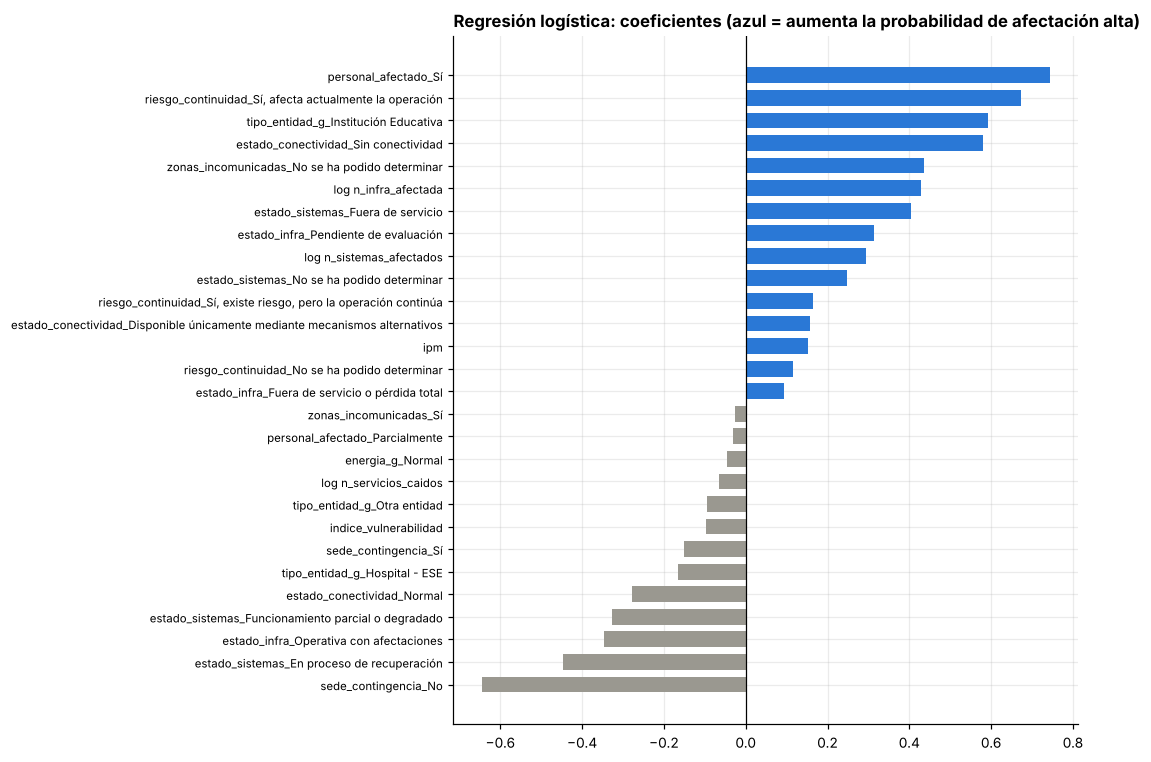

,Coeficiente (log-odds),Razón de odds
log n_infra_afectada,0.4289,1.5356
zonas_incomunicadas_No se ha podido determinar,0.4359,1.5463
estado_conectividad_Sin conectividad,0.5813,1.7884
tipo_entidad_g_Institución Educativa,0.5925,1.8085
"riesgo_continuidad_Sí, afecta actualmente la operación",0.6724,1.9590
personal_afectado_Sí,0.7432,2.1027
sede_contingencia_No,-0.6450,0.5247
estado_sistemas_En proceso de recuperación,-0.4478,0.6390
estado_infra_Operativa con afectaciones,-0.3468,0.7069
estado_sistemas_Funcionamiento parcial o degradado,-0.3264,0.7215


In [22]:
# Coeficientes y razones de odds (variables numéricas escaladas: efecto de aumentar 1 desviación estándar)
nombres = clf.named_steps['preprocesamiento'].get_feature_names_out()
coef_clf = pd.DataFrame({'Coeficiente (log-odds)': clf.named_steps['modelo'].coef_[0]}, index=nombres)
coef_clf['Razón de odds'] = np.exp(coef_clf['Coeficiente (log-odds)'])
coef_clf.index = coef_clf.index.str.replace('cualitativas__', '').str.replace('numericas__', '').str.replace('conteos__', 'log ')
coef_clf = coef_clf.sort_values('Coeficiente (log-odds)')
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(coef_clf.index, coef_clf['Coeficiente (log-odds)'], color=np.where(coef_clf['Coeficiente (log-odds)'] > 0, AZUL, GRIS), height=.7)
ax.axvline(0, color='black', lw=.8); ax.tick_params(axis='y', labelsize=7.5)
ax.set_title('Regresión logística: coeficientes (azul = aumenta la probabilidad de afectación alta)', loc='left')
plt.tight_layout(); plt.show()
display(pd.concat([coef_clf.tail(6), coef_clf.head(6)]).round(4))

**Interpretación del modelo logístico**

* La búsqueda en rejilla eligió **C = 0,1** (regularización moderada) y **pesos de clase balanceados**, con F1 = 0,8718 en la validación
  cruzada. La regularización fuerte tiene sentido: hay 28 columnas para 302 entidades y varias categorías se solapan.
* **Factores que aumentan la probabilidad de afectación alta** (razón de odds > 1): que el **personal TIC esté afectado** (OR = 2,10), que
  la afectación **ya impida la operación** (1,96), ser **institución educativa** (1,81), estar **sin conectividad** (1,79) y tener más
  **elementos de infraestructura afectados** (1,54 por cada desviación estándar del logaritmo del conteo).
* **Factores que la reducen** (razón de odds < 1): **no requerir sede de contingencia** (0,52), sistemas **en recuperación** o **con
  funcionamiento parcial** (0,64 y 0,72), infraestructura **operativa con afectaciones** (0,71) y **conectividad normal** (0,76).
* Las razones de odds son **condicionales** (manteniendo las demás variables constantes) y están reducidas por la regularización, así que
  se leen como dirección e importancia relativa, no como efectos causales.

## 8. Evaluación del modelo
Las métricas se calculan sobre el **conjunto de prueba** (25 %, datos que el modelo no vio) y se complementan con **validación cruzada
repetida** (5 pliegues × 10 repeticiones = 50 evaluaciones) sobre toda la base, para ver su estabilidad: con 403 entidades, una sola
partición de prueba puede caer en una muestra favorable o desfavorable.

### 8.1 Regresión lineal: MAE, RMSE, MAPE y R²
* **MAE:** error absoluto medio, en puntos del índice. **RMSE:** raíz del error cuadrático medio; penaliza más los errores grandes.
* **MAPE:** error porcentual absoluto medio. Como el índice vale **0 en algunas entidades** y el porcentaje no está definido al dividir por
  cero, se calcula sobre las entidades con índice > 0 (se informa cuántas quedan).
* **R²:** proporción de la varianza del índice que explica el modelo.

In [23]:
def metricas_reg(y, p):
    m = y > 0
    return {'MAE': mean_absolute_error(y, p), 'RMSE': np.sqrt(mean_squared_error(y, p)),
            'MAPE (%)': np.mean(np.abs((y[m] - p[m]) / y[m])) * 100, 'R²': r2_score(y, p), 'n (MAPE)': int(m.sum())}
tab_reg = pd.DataFrame({
    'Referencia (media)': metricas_reg(yr_te, reg_dummy.predict(Xr_te)),
    'Lineal simple (IPM)': metricas_reg(yr_te, reg_simple.predict(Xr_te)),
    'Lineal múltiple': metricas_reg(yr_te, reg.predict(Xr_te)),
    'Lineal múltiple (entrenamiento)': metricas_reg(yr_tr, reg.predict(Xr_tr))}).T
print(f'Conjunto de prueba: {len(yr_te)} entidades'); display(tab_reg.round(4))

# Una sola partición de 101 entidades puede ser optimista o pesimista. Validación cruzada repetida (5 pliegues × 10 repeticiones = 50
# evaluaciones) sobre toda la base, para ver la estabilidad de las métricas
cv_rep = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEMILLA)
cvr = cross_validate(pipeline_regresion(), df[NUM_REG + CAT_REG], df[Y_REG], cv=cv_rep,
                     scoring={'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R²': 'r2'})
vals = {k: np.abs(cvr[f'test_{k}']) if k != 'R²' else cvr[f'test_{k}'] for k in ['MAE', 'RMSE', 'R²']}
cv_reg = pd.DataFrame({k: {'Media': v.mean(), 'Desv. est.': v.std(), 'P5': np.percentile(v, 5), 'P95': np.percentile(v, 95)}
                       for k, v in vals.items()})
print('Validación cruzada repetida (5 pliegues × 10 repeticiones, toda la base):'); display(cv_reg.round(4))
print('Posición del R² de la partición de prueba dentro de las 50 evaluaciones: percentil',
      R(stats.percentileofscore(vals['R²'], r2_score(yr_te, reg.predict(Xr_te)))))

Conjunto de prueba: 101 entidades


,MAE,RMSE,MAPE (%),R²,n (MAPE)
Referencia (media),0.6854,0.9931,33.3746,-0.0025,93.0000
Lineal simple (IPM),0.7042,0.9790,34.4388,0.0257,93.0000
Lineal múltiple,0.7359,0.9585,36.9497,0.0661,93.0000
Lineal múltiple (entrenamiento),0.6876,0.9068,34.5165,0.3409,270.0000


Validación cruzada repetida (5 pliegues × 10 repeticiones, toda la base):


,MAE,RMSE,R²
Media,0.7132,0.9410,0.2318
Desv. est.,0.0550,0.0629,0.0883
P5,0.6200,0.8483,0.0776
P95,0.8001,1.0464,0.3603


Posición del R² de la partición de prueba dentro de las 50 evaluaciones: percentil 4.0


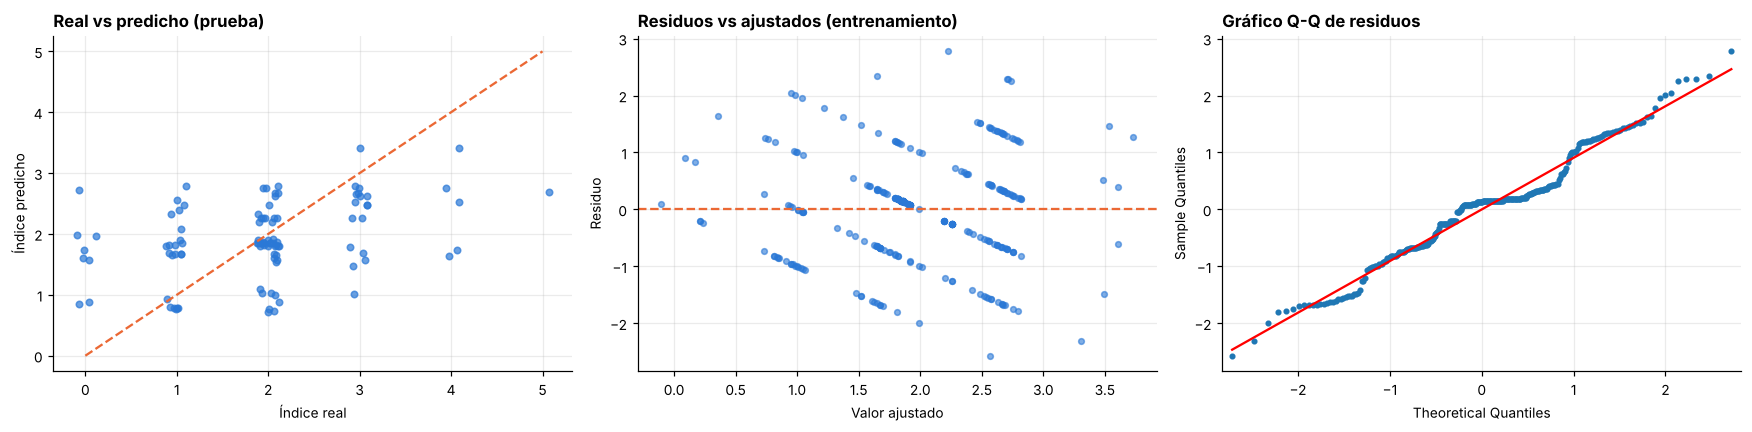

In [24]:
pred_te = reg.predict(Xr_te); res_tr = ols.resid
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
jit = np.random.default_rng(1).uniform(-.12, .12, len(yr_te))
axs[0].scatter(yr_te + jit, pred_te, s=18, color=AZUL, alpha=.7); axs[0].plot([0, 5], [0, 5], color=NARANJA, ls='--')
axs[0].set_xlabel('Índice real'); axs[0].set_ylabel('Índice predicho'); axs[0].set_title('Real vs predicho (prueba)', loc='left')
axs[1].scatter(ols.fittedvalues, res_tr, s=14, color=AZUL, alpha=.6); axs[1].axhline(0, color=NARANJA, ls='--')
axs[1].set_xlabel('Valor ajustado'); axs[1].set_ylabel('Residuo'); axs[1].set_title('Residuos vs ajustados (entrenamiento)', loc='left')
sm.qqplot(res_tr, line='s', ax=axs[2], markersize=3, color=AZUL); axs[2].set_title('Gráfico Q-Q de residuos', loc='left')
plt.tight_layout(); plt.show()

**Validación de supuestos del modelo lineal** (sobre los residuos del entrenamiento):

| Supuesto | Prueba | H₀ |
|---|---|---|
| Normalidad de los residuos | Shapiro-Wilk y Jarque-Bera | Los residuos son normales |
| Homocedasticidad | Breusch-Pagan | La varianza de los residuos es constante |
| Independencia | Durbin-Watson (≈ 2 indica independencia) | No hay autocorrelación |
| No multicolinealidad | Factor de inflación de varianza (VIF < 5) | — |

In [25]:
sw_res = stats.shapiro(res_tr); jb = stats.jarque_bera(res_tr)
bp = het_breuschpagan(res_tr, ols.model.exog)
sup = pd.DataFrame([
    {'Supuesto': 'Normalidad', 'Prueba': 'Shapiro-Wilk', 'Estadístico': sw_res.statistic, 'p-valor': sw_res.pvalue},
    {'Supuesto': 'Normalidad', 'Prueba': 'Jarque-Bera', 'Estadístico': jb.statistic, 'p-valor': jb.pvalue},
    {'Supuesto': 'Homocedasticidad', 'Prueba': 'Breusch-Pagan (LM)', 'Estadístico': bp[0], 'p-valor': bp[1]},
    {'Supuesto': 'Independencia', 'Prueba': 'Durbin-Watson', 'Estadístico': durbin_watson(res_tr), 'p-valor': np.nan}])
sup['Conclusión (α = 0,05)'] = np.where(sup['p-valor'].isna(), 'Cerca de 2: sin autocorrelación' if 1.5 < durbin_watson(res_tr) < 2.5 else 'Revisar',
                                        np.where(sup['p-valor'] < .05, 'Se rechaza H₀', 'No se rechaza H₀'))
display(sup.round(4))
X_vif = ols.model.exog; vif = pd.Series([variance_inflation_factor(X_vif, i) for i in range(1, X_vif.shape[1])],
                                        index=tabla_ols.index[1:], name='VIF')
display(vif.round(4).to_frame())
# Errores estándar robustos a heterocedasticidad (HC3): ¿cambian las conclusiones sobre los coeficientes?
ols_hc3 = ols.get_robustcov_results(cov_type='HC3')
display(pd.DataFrame({'p-valor clásico': ols.pvalues.values, 'p-valor robusto (HC3)': ols_hc3.pvalues}, index=tabla_ols.index).round(4))

,Supuesto,Prueba,Estadístico,p-valor,"Conclusión (α = 0,05)"
0,Normalidad,Shapiro-Wilk,0.9743,0.0000,Se rechaza H₀
1,Normalidad,Jarque-Bera,0.8021,0.6696,No se rechaza H₀
2,Homocedasticidad,Breusch-Pagan (LM),53.2336,0.0000,Se rechaza H₀
3,Independencia,Durbin-Watson,2.1824,NaN,Cerca de 2: sin autocorrelación


,VIF
Depto: CHOCÓ,2.9649
Depto: QUINDÍO,1.7268
Depto: RISARALDA,3.3977
Depto: VALLE DEL CAUCA,2.7571
Tipo: Hospital - ESE,1.5079
Tipo: Institución Educativa,2.5603
Tipo: Otra entidad,1.6987
ipm,2.3264


,p-valor clásico,p-valor robusto (HC3)
Intercept,0.0000,0.0003
Depto: CHOCÓ,0.1252,0.2398
Depto: QUINDÍO,0.0227,0.0764
Depto: RISARALDA,0.0000,0.0002
Depto: VALLE DEL CAUCA,0.7510,0.8054
Tipo: Hospital - ESE,0.0089,0.0264
Tipo: Institución Educativa,0.0000,0.0000
Tipo: Otra entidad,0.2922,0.3608
ipm,0.0131,0.0099


**Interpretación de la evaluación de la regresión lineal**

* **Partición de prueba:** el modelo múltiple tiene un R² de solo 0,0661 y un MAE de 0,7359 puntos, apenas por encima del modelo de
  referencia en RMSE (0,9585 frente a 0,9931) y peor en MAE y MAPE. El MAPE (36,95 %, calculado sobre 93 entidades con índice > 0) indica
  que el error típico es de alrededor de un tercio del valor del índice.
* **Esa partición es desfavorable:** en la validación cruzada repetida el R² medio es **0,2318** (P5 = 0,0776; P95 = 0,3603) y el R² de la
  partición de prueba queda en el **percentil 4** de las 50 evaluaciones. Con solo 101 entidades en prueba, el R² varía mucho según cuáles
  queden en ella. La estimación más confiable es la de la validación cruzada: **el modelo explica cerca del 23 % de la variabilidad del
  índice**, con un error medio de 0,71 puntos en una escala de 0 a 5.
* **Sobreajuste moderado:** R² de 0,3409 en entrenamiento frente a 0,2318 en validación cruzada.
* **Supuestos:**
  * *Normalidad:* Shapiro-Wilk la rechaza (p < 0,0001), pero Jarque-Bera no (p = 0,6696). La asimetría y la curtosis de los residuos son
    normales; Shapiro detecta los "escalones" de una respuesta discreta (visibles en el Q-Q). Con 302 observaciones, el teorema del límite
    central protege las pruebas t.
  * *Homocedasticidad:* Breusch-Pagan **la rechaza** (p < 0,0001); la varianza de los residuos cambia según el grupo. Por eso se
    recalcularon los p-valores con **errores estándar robustos (HC3)**: el IPM, Risaralda, instituciones educativas y hospitales siguen
    siendo significativos; Quindío deja de serlo (p = 0,0764).
  * *Independencia:* Durbin-Watson = 2,18, sin autocorrelación.
  * *Multicolinealidad:* todos los VIF están por debajo de 3,4 (umbral 5).
* **Conclusión:** el modelo es **estadísticamente significativo e interpretable**, pero su **capacidad predictiva es limitada**. El
  territorio y el tipo de entidad explican una parte de la fragilidad digital; el resto depende de condiciones propias de cada entidad que
  solo se conocen con la encuesta. Sirve para **priorizar grupos** (por ejemplo, colegios de municipios muy pobres), no para predecir el
  índice exacto de una entidad.

### 8.2 Regresión logística: Accuracy, Precision, Recall y F1-score
* **Accuracy:** % de entidades bien clasificadas. **Precision:** de las que el modelo marca como afectación alta, cuántas lo son.
  **Recall (exhaustividad):** de las que realmente están en afectación alta, cuántas detecta el modelo. **F1:** media armónica de las dos.
* Se agrega **AUC-ROC** (capacidad de ordenar por riesgo, independiente del umbral), por recomendación del profesor de no depender de una sola
  métrica.

In [26]:
def metricas_clf(y, p, prob=None):
    out = {'Accuracy': accuracy_score(y, p), 'Precision': precision_score(y, p, zero_division=0),
           'Recall': recall_score(y, p), 'F1-score': f1_score(y, p)}
    out['AUC-ROC'] = roc_auc_score(y, prob) if prob is not None else np.nan
    return out
prob_te = clf.predict_proba(Xc_te)[:, 1]; pc_te = clf.predict(Xc_te)
tab_clf = pd.DataFrame({
    'Referencia (clase mayoritaria)': metricas_clf(yc_te, clf_dummy.predict(Xc_te)),
    'Regresión logística (prueba)': metricas_clf(yc_te, pc_te, prob_te),
    'Regresión logística (entrenamiento)': metricas_clf(yc_tr, clf.predict(Xc_tr), clf.predict_proba(Xc_tr)[:, 1])}).T
display(tab_clf.round(4))
print(classification_report(yc_te, pc_te, target_names=['Baja (0)', 'Alta/Crítica (1)'], digits=4))

,Accuracy,Precision,Recall,F1-score,AUC-ROC
Referencia (clase mayoritaria),0.5149,0.5149,1.0000,0.6797,NaN
Regresión logística (prueba),0.9010,0.9375,0.8654,0.9000,0.9749
Regresión logística (entrenamiento),0.8874,0.9357,0.8397,0.8851,0.9474


                  precision    recall  f1-score   support

        Baja (0)     0.8679    0.9388    0.9020        49
Alta/Crítica (1)     0.9375    0.8654    0.9000        52

        accuracy                         0.9010       101
       macro avg     0.9027    0.9021    0.9010       101
    weighted avg     0.9037    0.9010    0.9010       101



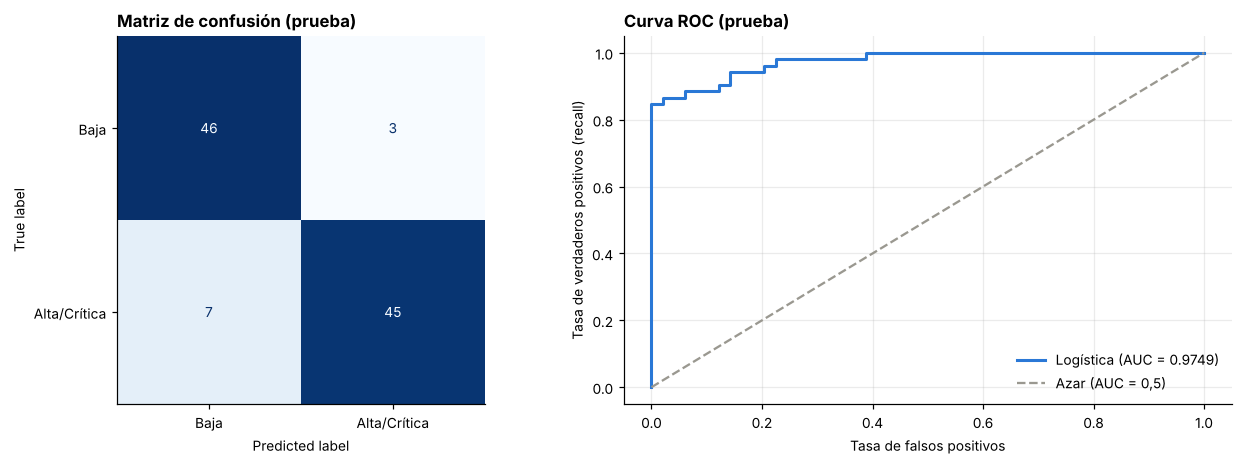

In [27]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
ConfusionMatrixDisplay(confusion_matrix(yc_te, pc_te), display_labels=['Baja', 'Alta/Crítica']).plot(ax=axs[0], cmap='Blues', colorbar=False)
axs[0].set_title('Matriz de confusión (prueba)', loc='left'); axs[0].grid(False)
fpr, tpr, _ = roc_curve(yc_te, prob_te)
axs[1].plot(fpr, tpr, color=AZUL, lw=2, label=f'Logística (AUC = {roc_auc_score(yc_te, prob_te):.4f})')
axs[1].plot([0, 1], [0, 1], color=GRIS, ls='--', label='Azar (AUC = 0,5)')
axs[1].set_xlabel('Tasa de falsos positivos'); axs[1].set_ylabel('Tasa de verdaderos positivos (recall)')
axs[1].set_title('Curva ROC (prueba)', loc='left'); axs[1].legend(frameon=False)
plt.tight_layout(); plt.show()

In [28]:
# Validación cruzada repetida (5 × 10) sobre toda la base y análisis de sensibilidad sin el bloque de Risaralda
mejor = dict(C=rejilla.best_params_['modelo__C'], class_weight=rejilla.best_params_['modelo__class_weight'])
ESC = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
filas = {}
for nombre, base_cv in [('Toda la base', df), ('Sin Risaralda', df[df['departamento'] != 'RISARALDA'])]:
    r = cross_validate(pipeline_clasificacion(**mejor), base_cv[NUM_CLF + CAT_CLF], base_cv[Y_CLF], scoring=ESC,
                       cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEMILLA))
    filas[f'{nombre} (n = {len(base_cv)}, % clase 1 = {base_cv[Y_CLF].mean() * 100:.1f})'] = {k: r[f'test_{k}'].mean() for k in ESC}
cv_clf = pd.DataFrame(filas).T; cv_clf.columns = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'AUC-ROC']
display(cv_clf.round(4))
# Desempeño en prueba por grupo
g = te.assign(pred=pc_te, prob=prob_te).groupby(np.where(te['departamento'] == 'RISARALDA', 'Risaralda', 'Otros 4 departamentos'))
display(pd.DataFrame({k: metricas_clf(v[Y_CLF], v['pred'], v['prob'] if v[Y_CLF].nunique() > 1 else None) | {'n': len(v)}
                      for k, v in g}).T.round(4))

,Accuracy,Precision,Recall,F1-score,AUC-ROC
"Toda la base (n = 403, % clase 1 = 51.6)",0.8792,0.9382,0.8207,0.8746,0.9436
"Sin Risaralda (n = 237, % clase 1 = 24.5)",0.7459,0.4917,0.6665,0.5603,0.8329


,Accuracy,Precision,Recall,F1-score,AUC-ROC,n
Otros 4 departamentos,0.8333,0.7143,0.4167,0.5263,0.9107,54.0000
Risaralda,0.9787,0.9756,1.0000,0.9877,1.0000,47.0000


**Interpretación de la evaluación de la regresión logística**

* **Partición de prueba (101 entidades):** accuracy = **0,9010**, precision = **0,9375**, recall = **0,8654**, F1 = **0,9000** y AUC-ROC =
  **0,9749**. El modelo supera con claridad a la referencia (accuracy 0,5149). En la matriz de confusión hay 3 falsos positivos y 7
  falsos negativos: es más común que el modelo **pase por alto** una entidad en afectación alta que lo contrario.
* **Estabilidad:** en la validación cruzada repetida (toda la base) las métricas son muy parecidas (accuracy 0,8792; F1 0,8746; AUC 0,9436),
  y entrenamiento y prueba están cerca: **no hay sobreajuste**.
* **Análisis de sensibilidad (lo más importante):** el desempeño depende en gran parte del **bloque de Risaralda**. En la prueba, el modelo
  acierta el 97,87 % en Risaralda, pero en los otros 4 departamentos su **recall cae a 0,4167** (detecta 5 de cada 12 entidades en
  afectación alta). Si se entrena y valida **sin Risaralda**, el F1 baja a **0,5603** y la precision a 0,4917, aunque el AUC se mantiene en
  0,8329.
* **Lectura:** con toda la base, parte de lo que aprende el modelo es a reconocer el **patrón de respuesta** del bloque de colegios de
  Risaralda (respuestas idénticas, "no se ha podido determinar", sede en evaluación). Sin ese bloque, el modelo todavía **ordena bien el
  riesgo** (AUC 0,83), pero con el umbral de 0,5 tiene muchos falsos positivos. Para usarlo fuera de Risaralda convendría reentrenarlo sin
  ese bloque y ajustar el umbral según qué error sea más costoso para MinTIC (dejar sin atención a una entidad crítica es más grave, así
  que se privilegiaría el recall).

## 9. Conclusiones

1. **Se construyeron los dos modelos que pide el laboratorio**, cada uno con su pipeline (imputación, logaritmo de los conteos,
   escalamiento y one-hot) y evaluado sobre datos no vistos y con validación cruzada repetida.
2. **Clasificación (regresión logística):** predice si una entidad está en afectación **Alta o Crítica** con accuracy 0,90, precision 0,94,
   recall 0,87, F1 0,90 y AUC 0,97 en prueba. Las variables que más pesan son el **personal TIC afectado**, que la afectación **ya impida la
   operación**, la **falta de conectividad** y el **número de elementos de infraestructura afectados**, las mismas que el Lab 2 destacó por
   su V de Cramér.
3. **Ese desempeño está inflado por el bloque de Risaralda.** Sin él, el F1 baja a 0,56 (AUC 0,83). Hay que **validar ese bloque con
   MinTIC** antes de usar el modelo para decisiones, y presentar siempre las métricas con y sin Risaralda.
4. **Regresión (regresión lineal):** el índice de vulnerabilidad aumenta **0,0118 puntos por cada punto de IPM**, es 1,11 puntos mayor en
   las **instituciones educativas** que en las alcaldías y 0,65 menor en los hospitales. El modelo es significativo (F = 18,94, p < 0,0001),
   pero explica solo **~23 % de la variabilidad** (R² en validación cruzada; MAE 0,71). Sirve para priorizar **grupos** de entidades, no
   para estimar con precisión cada una.
5. **Pruebas de hipótesis:** se usaron χ², Mann-Whitney, Spearman y Kruskal-Wallis con corrección de Holm por pruebas múltiples, y en el
   modelo lineal se verificaron sus supuestos. Breusch-Pagan detectó **heterocedasticidad**, y por eso los coeficientes se interpretaron
   con **errores estándar robustos (HC3)**.
6. **El hallazgo de los tres laboratorios se mantiene:** la pobreza del municipio **no explica la afectación que declara** la entidad (el
   índice de vulnerabilidad ni siquiera se asocia con la clase), pero **sí explica su fragilidad estructural**. Priorizar solo por
   autoevaluación puede relegar a entidades del **Chocó**, que declaran afectaciones similares, pero son más frágiles.
7. **Siguientes pasos:** reentrenar la clasificación sin el bloque de Risaralda y ajustar el umbral para privilegiar el recall; probar un
   modelo de regresión de Poisson u ordinal, más adecuado para un conteo de 0 a 5; e incorporar la pobreza de 2025-2026 cuando el DANE la
   publique.

### Exportación de modelos y base de modelación
Se guardan los dos pipelines entrenados (con su preprocesamiento) y la base de modelación con la columna `conjunto`
(entrenamiento / prueba). La app de Streamlit los carga para mostrar las métricas y hacer predicciones.

In [29]:
joblib.dump(reg, MODELOS / 'regresion_lineal.joblib')
joblib.dump(clf, MODELOS / 'regresion_logistica.joblib')
meta = {'sklearn': sklearn.__version__, 'semilla': SEMILLA,
        'regresion': {'respuesta': Y_REG, 'numericas': NUM_REG, 'cualitativas': CAT_REG},
        'clasificacion': {'respuesta': Y_CLF, 'numericas': NUM_CLF, 'cualitativas': CAT_CLF, 'hiperparametros': mejor}}
tab_esc.to_csv(MODELOS / 'comparacion_escaladores.csv', encoding='utf-8-sig')
(MODELOS / 'metadatos.json').write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding='utf-8')
cols = ['id', 'razon_social', 'departamento', 'municipio', 'cod_mpio', 'tipo_entidad', 'nivel_afectacion_cat', 'conjunto', Y_CLF,
        *[c for c in dict.fromkeys(NUM_CLF + CAT_CLF + NUM_REG + CAT_REG) if c not in (Y_CLF,)]]
df[cols].to_csv(PROC / 'base_lab3.csv', index=False, encoding='utf-8-sig')
print('Guardados: models/regresion_lineal.joblib, models/regresion_logistica.joblib, models/metadatos.json, models/comparacion_escaladores.csv y data/processed/base_lab3.csv', df[cols].shape)

Guardados: models/regresion_lineal.joblib, models/regresion_logistica.joblib, models/metadatos.json, models/comparacion_escaladores.csv y data/processed/base_lab3.csv (403, 24)
